In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv("american_bankruptcy_dataset.csv")

display(df.head())

,company_name,fyear,status_label,X1,X2,X3,X4,X5,X6,X7,...,X11,X12,X13,X14,X15,X16,X17,X18,Division,MajorGroup
0,C_1,1999.0,alive,511267.0,740998.000,833107.0,180447.0,18373.00,70658.00,89031.000,...,35.163,201026.000,128.348,1024333.000,372.7519,401483.0,1024333.000,935302.0,D,37
1,C_1,2000.0,alive,485856.0,701.854,713811.0,179987.0,18577.00,45.79,64367.000,...,18531.000,204065.000,115187.000,874255.000,377.1180,361642.0,874255.000,809888.0,D,37
2,C_1,2001.0,alive,436656.0,710199.000,526477.0,217699.0,22496.00,4711.00,27207.000,...,-58.939,139.603,77528.000,638721.000,364.5928,399964.0,638721.000,611514.0,D,37
3,C_1,2002.0,alive,396412.0,686.621,496747.0,164658.0,27172.00,3573.00,30745.000,...,-12.410,124106.000,66322.000,606337.000,143.3295,391633.0,606337.000,575592.0,D,37
4,C_1,2003.0,alive,432204.0,709.292,523302.0,248666.0,26.68,20811.00,47.491,...,3504.000,131884.000,104661.000,651.958,308.9071,407608.0,651.958,604467.0,D,37


## 1.1. Podstawowe informacje o zbiorze danych

W analizie wykorzystano American Bankruptcy Dataset, obejmujący
historyczne dane finansowe amerykańskich przedsiębiorstw giełdowych
z lat 1999–2018.

Celem analizy jest poznanie struktury zbioru, sprawdzenie jakości danych
oraz identyfikacja cech, które mogą być przydatne do przewidywania
bankructwa przedsiębiorstw.

In [6]:
print("Liczba obserwacji:", df.shape[0])
print("Liczba kolumn:", df.shape[1])
print("Liczba przedsiębiorstw:", df["company_name"].nunique())

print("\nNazwy kolumn:")
print(df.columns.tolist())

print("\nTypy danych:")
df.info()

Liczba obserwacji: 78682
Liczba kolumn: 23
Liczba przedsiębiorstw: 8971

Nazwy kolumn:
['company_name', 'fyear', 'status_label', 'X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16', 'X17', 'X18', 'Division', 'MajorGroup']

Typy danych:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 78682 entries, 0 to 78681
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   company_name  78682 non-null  object 
 1   fyear         78682 non-null  float64
 2   status_label  78682 non-null  object 
 3   X1            78682 non-null  float64
 4   X2            78682 non-null  float64
 5   X3            78682 non-null  float64
 6   X4            78682 non-null  float64
 7   X5            78682 non-null  float64
 8   X6            78682 non-null  float64
 9   X7            78682 non-null  float64
 10  X8            78682 non-null  float64
 11  X9            78682 non-null  float64
 12

## 1.2. Kontrola jakości danych

Przed rozpoczęciem modelowania sprawdzono występowanie brakujących
wartości, zduplikowanych obserwacji oraz wartości nieskończonych.

Kontrola jakości danych pozwala ustalić, czy konieczne jest ich
dodatkowe czyszczenie.

In [7]:
print("Łączna liczba braków:", df.isna().sum().sum())

print("Liczba duplikatów wierszy:", df.duplicated().sum())

print(
    "Duplikaty przedsiębiorstwo-rok:",
    df.duplicated(subset=["company_name", "fyear"]).sum()
)

kolumny_liczbowe = df.select_dtypes(include="number")

print(
    "Liczba wartości nieskończonych:",
    np.isinf(kolumny_liczbowe).sum().sum()
)

display(df.isna().sum().to_frame("Liczba braków"))

Łączna liczba braków: 0
Liczba duplikatów wierszy: 0
Duplikaty przedsiębiorstwo-rok: 0
Liczba wartości nieskończonych: 0


,Liczba braków
company_name,0
fyear,0
status_label,0
X1,0
X2,0
X3,0
X4,0
X5,0
X6,0
X7,0


## 1.3. Rozkład zmiennej celu

Zmienna status_label przyjmuje dwie wartości:

- alive – przedsiębiorstwo bez oznaczonego zdarzenia bankructwa,
- failed – rok finansowy poprzedzający zgłoszenie bankructwa.

Analiza rozkładu klas pozwala określić, czy zbiór jest zrównoważony.

,Liczba obserwacji,Udział (%)
status_label,,
alive,73462,93.37
failed,5220,6.63


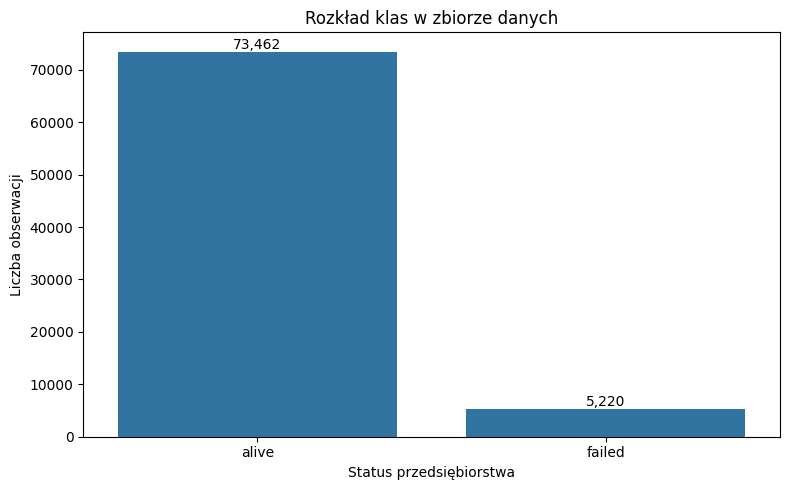

In [9]:
liczebnosci = df["status_label"].value_counts()
procenty = df["status_label"].value_counts(normalize=True) * 100

display(pd.DataFrame({
    "Liczba obserwacji": liczebnosci,
    "Udział (%)": procenty.round(2)
}))

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="status_label",
    order=["alive", "failed"]
)

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha="center",
        va="bottom"
    )

plt.title("Rozkład klas w zbiorze danych")
plt.xlabel("Status przedsiębiorstwa")
plt.ylabel("Liczba obserwacji")
plt.tight_layout()
plt.show()

## 1.4. Analiza bankructw w latach 1999–2018

W tej części zbadano, jak zmieniała się liczba i częstotliwość
bankructw przedsiębiorstw w kolejnych latach.

Analiza pozwala ocenić, czy udział bankructw pozostawał
na podobnym poziomie w całym okresie badawczym.

,liczba_firm,bankructwa,procent
fyear,,,
1999.0,5308,380,7.159005
2000.0,5226,404,7.730578
2001.0,4897,414,8.454156
2002.0,4651,414,8.901312
2003.0,4417,415,9.395517
2004.0,4348,404,9.291628
2005.0,4205,379,9.013080
2006.0,4128,366,8.866279
2007.0,4009,336,8.381142


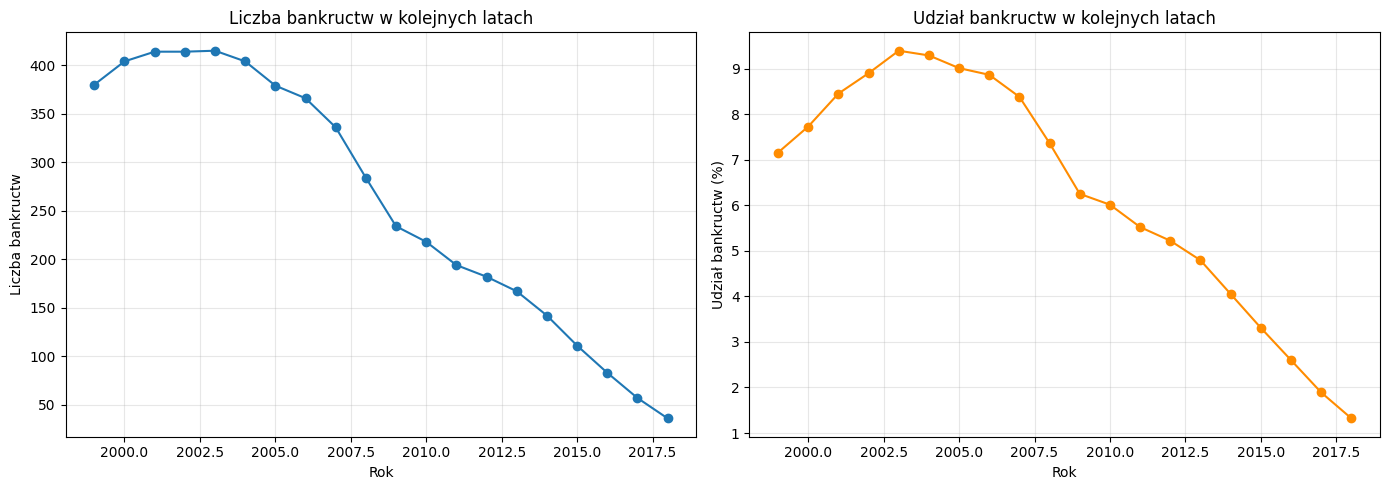

In [10]:
bankructwa_lata = df.groupby("fyear").agg(
    liczba_firm=("company_name", "count"),
    bankructwa=("status_label", lambda x: (x == "failed").sum())
)

bankructwa_lata["procent"] = (
    bankructwa_lata["bankructwa"]
    / bankructwa_lata["liczba_firm"] * 100
)

display(bankructwa_lata)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(
    bankructwa_lata.index,
    bankructwa_lata["bankructwa"],
    marker="o"
)
ax[0].set_title("Liczba bankructw w kolejnych latach")
ax[0].set_xlabel("Rok")
ax[0].set_ylabel("Liczba bankructw")
ax[0].grid(alpha=0.3)

ax[1].plot(
    bankructwa_lata.index,
    bankructwa_lata["procent"],
    marker="o",
    color="darkorange"
)
ax[1].set_title("Udział bankructw w kolejnych latach")
ax[1].set_xlabel("Rok")
ax[1].set_ylabel("Udział bankructw (%)")
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 1.5. Statystyki opisowe

Przeprowadzono analizę statystyczną 18 zmiennych finansowych.

Obliczono średnią, medianę, odchylenie standardowe, wartości
minimalne i maksymalne oraz kwartyle.

Celem analizy jest poznanie skali i zmienności poszczególnych
cech finansowych.

In [11]:
cechy = [f"X{i}" for i in range(1, 19)]

statystyki = df[cechy].describe().T

statystyki["mediana"] = df[cechy].median()

display(statystyki.round(2))

,count,mean,std,min,25%,50%,75%,max,mediana
X1,78682.0,213314.08,701629.10,-2498.00,1272.00,22016.50,153994.00,31322583.0,22016.50
X2,78682.0,599470.89,2065451.51,0.01,3282.52,43266.50,329362.00,67234944.0,43266.50
X3,78682.0,379774.46,2021659.41,-366645.00,1439.10,21044.50,180821.50,163245615.0,21044.50
X4,78682.0,150843.34,711505.23,-23.00,0.00,500.00,16010.50,20687082.0,500.00
X5,78682.0,24715.65,97781.69,0.00,74.40,1216.00,12344.75,4440438.0,1216.00
X6,78682.0,44261.77,224001.73,-5043795.00,-767.75,303.00,19097.75,9783515.0,303.00
X7,78682.0,69421.15,284799.37,-4512135.00,-9.00,1121.90,33256.75,12566722.0,1121.90
X8,78682.0,172375.67,600752.29,-4367571.00,355.43,11459.50,109900.00,27864399.0,11459.50
X9,78682.0,51021.66,220407.62,0.00,0.00,675.00,16771.75,11918508.0,675.00
X10,78682.0,123397.13,487710.00,0.01,958.08,10866.00,69280.50,27869687.0,10866.00


## 1.6. Rozkłady zmiennych finansowych

Histogramy przedstawiają rozkłady wartości zmiennych X1–X18.

Analiza umożliwia wykrycie asymetrii, dużego zróżnicowania
wartości oraz potencjalnych obserwacji odstających.

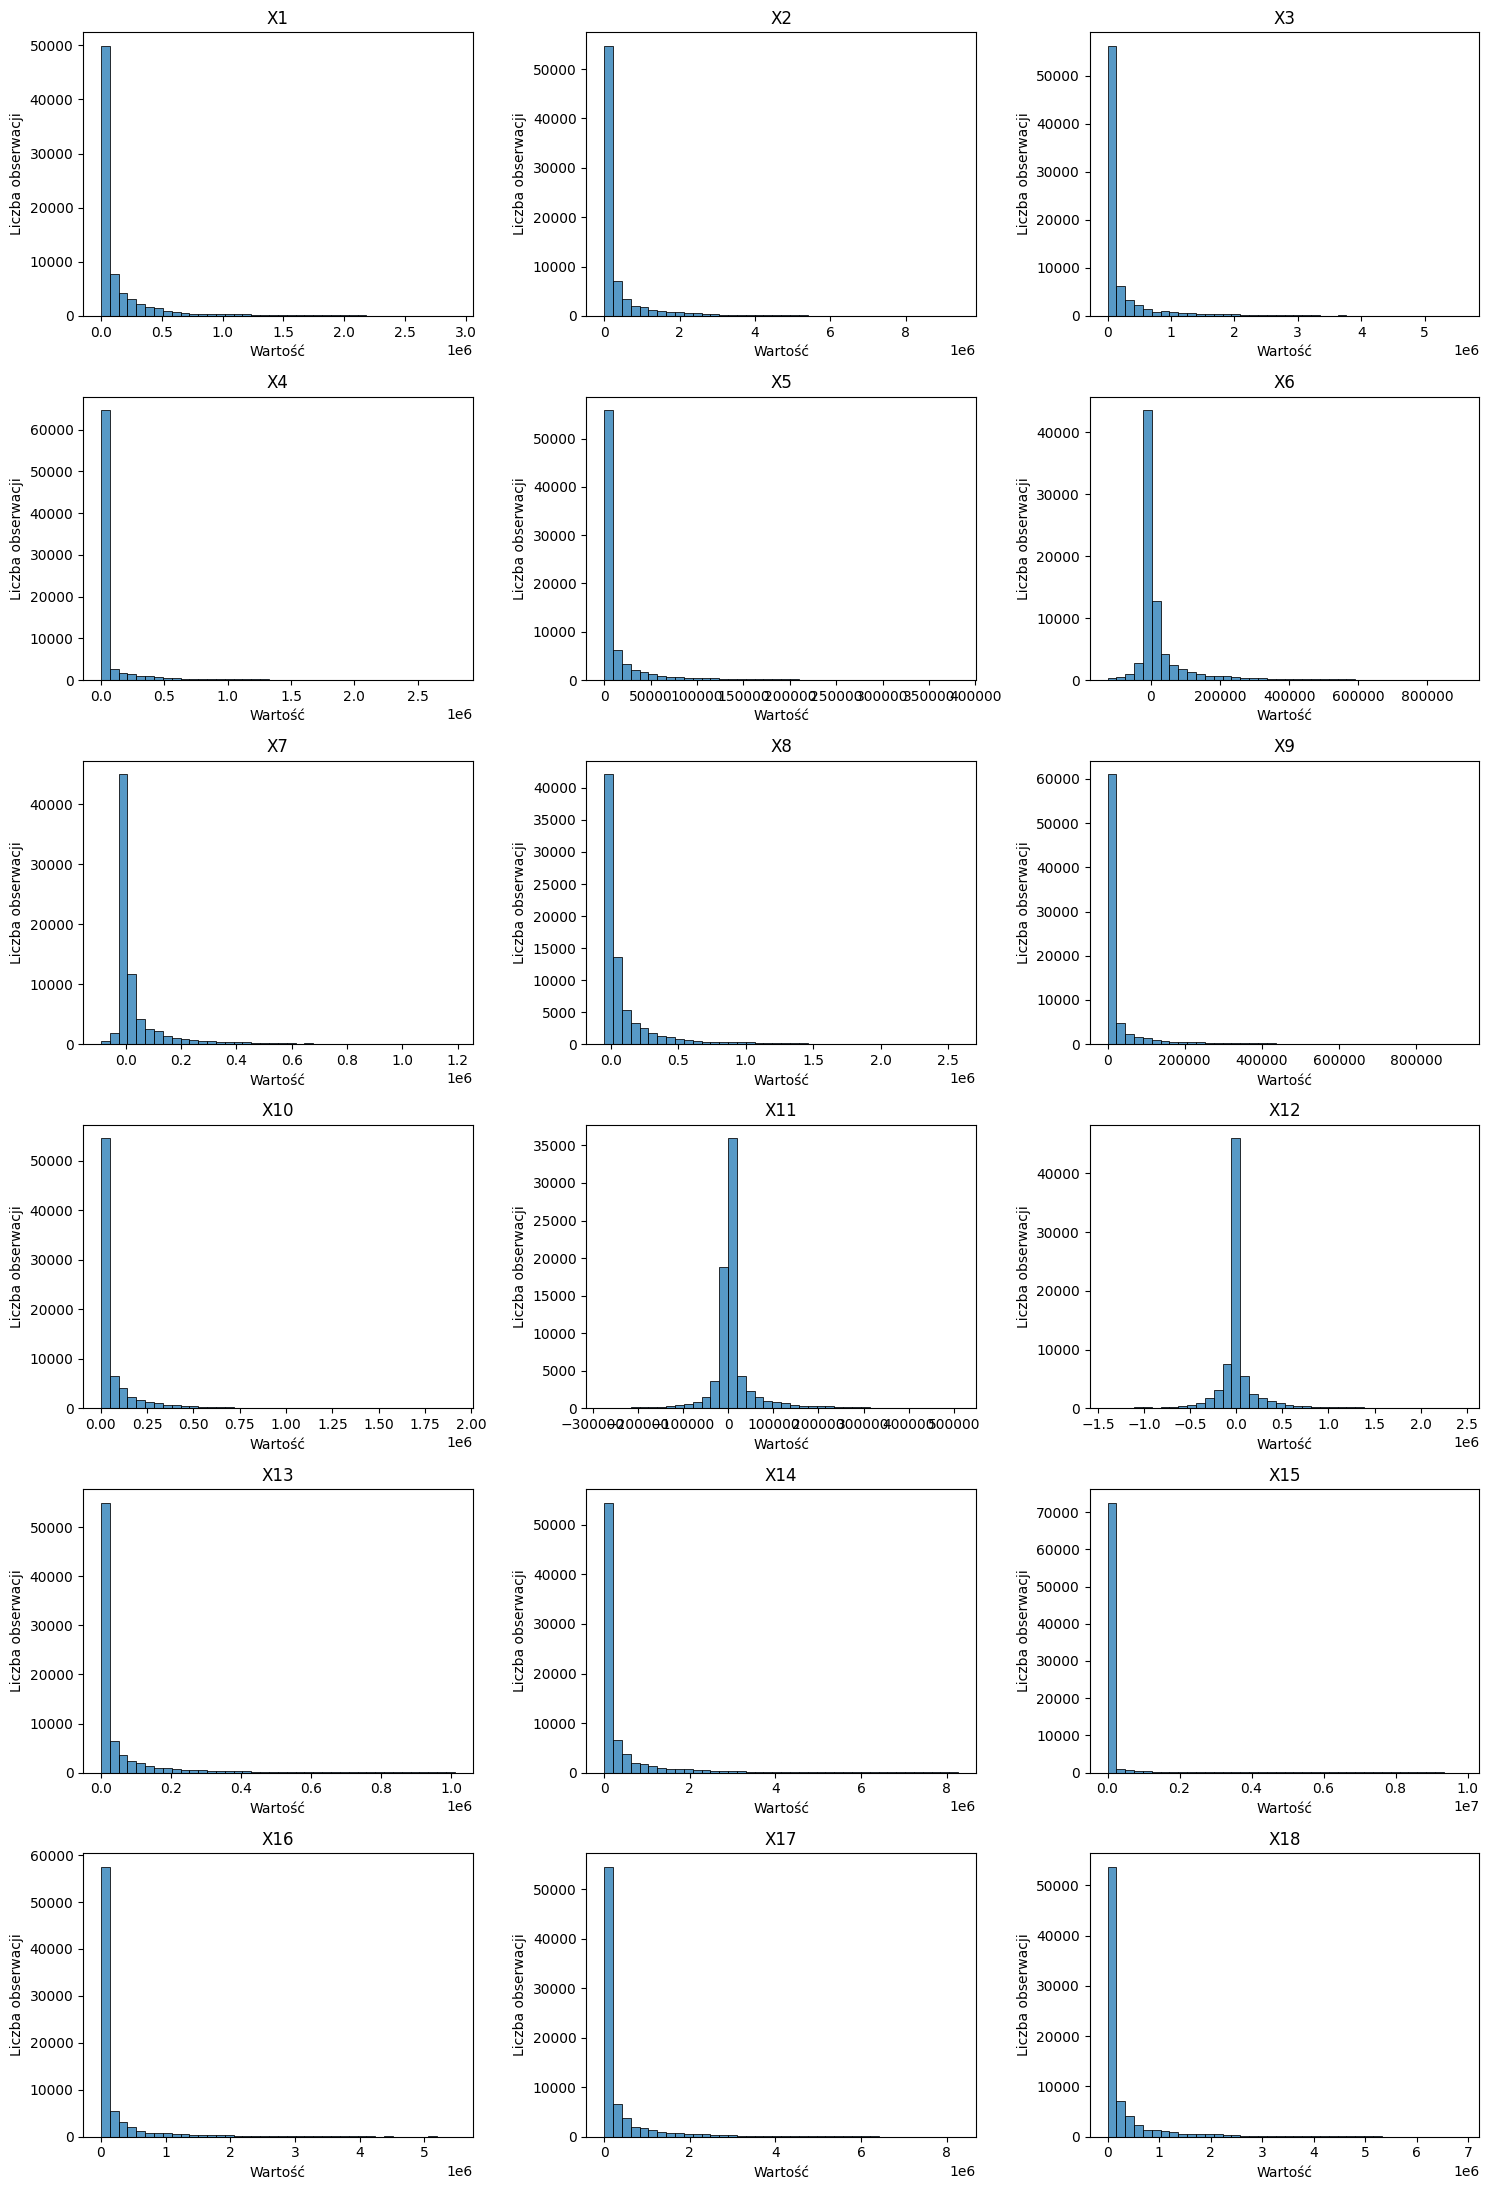

In [12]:
fig, axes = plt.subplots(6, 3, figsize=(15, 22))

for i, kolumna in enumerate(cechy):
    ax = axes.flat[i]

    dane = df[kolumna].dropna()

    # Ograniczamy zakres wizualizacji do percentyli 1–99.
    dol = dane.quantile(0.01)
    gora = dane.quantile(0.99)

    sns.histplot(
        dane[(dane >= dol) & (dane <= gora)],
        bins=40,
        ax=ax
    )

    ax.set_title(kolumna)
    ax.set_xlabel("Wartość")
    ax.set_ylabel("Liczba obserwacji")

plt.tight_layout()
plt.show()

## 1.7. Analiza korelacji

W celu zbadania zależności liniowych pomiędzy zmiennymi
finansowymi obliczono współczynniki korelacji Pearsona.

Wysoka korelacja może wskazywać, że wybrane zmienne
zawierają podobne informacje.

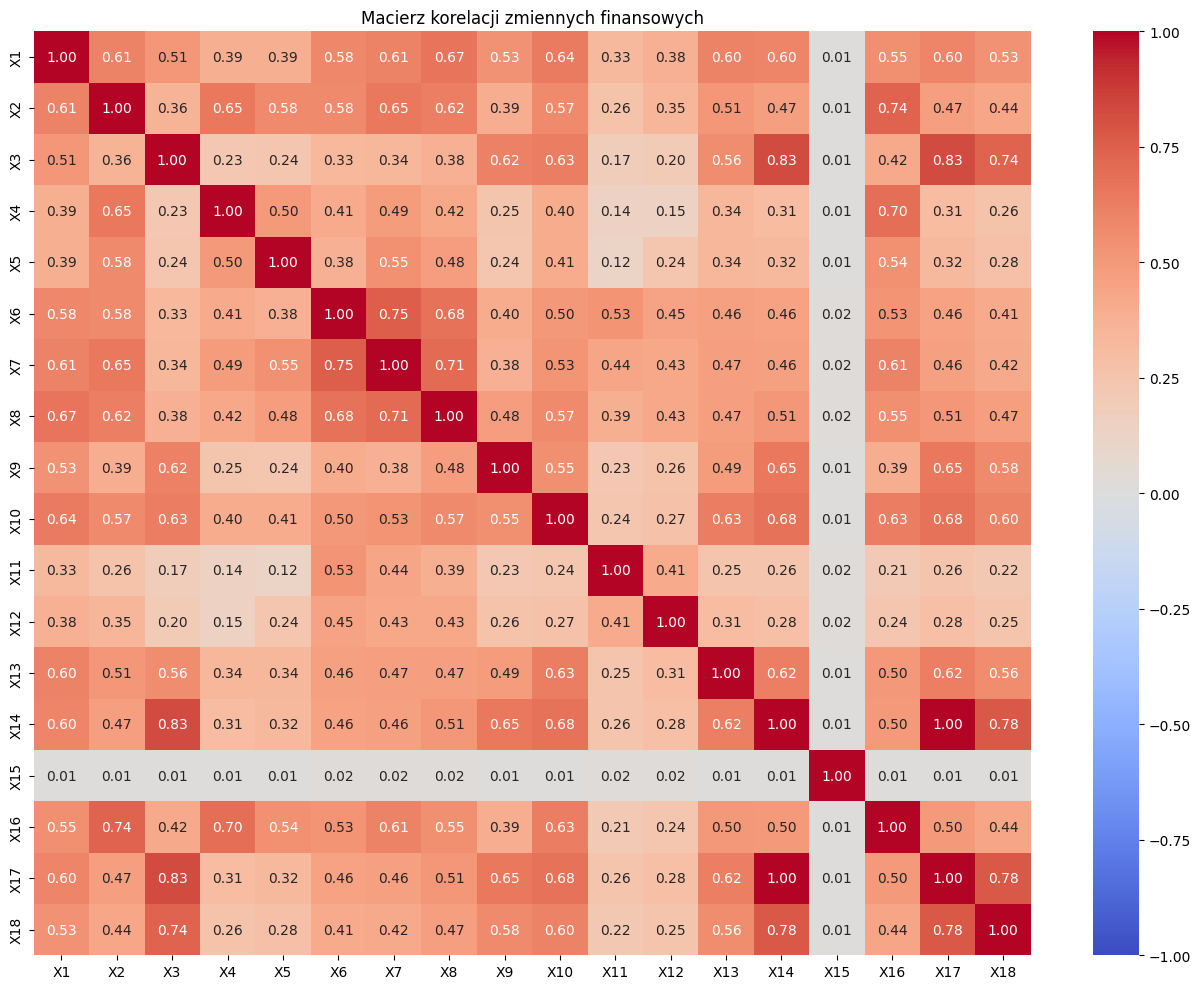

In [13]:
korelacje = df[cechy].corr()

plt.figure(figsize=(13, 10))

sns.heatmap(
    korelacje,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Macierz korelacji zmiennych finansowych")
plt.tight_layout()
plt.show()